In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [3]:
from google.colab import files

uploaded = files.upload()

Saving online_job_listings_salary_dataset.csv to online_job_listings_salary_dataset.csv


In [4]:
#Load dataset
df = pd.read_csv('online_job_listings_salary_dataset.csv')

df.head()

,Job_ID,Job_Title,Company,Location,Job_Type,Experience_Level,Experience_Years,Education,Skills,Salary_LPA,Posting_Age_Days
0,JOB0001,Python Developer,NextGen Software,Chennai,Full-time,5-8 Years,6.8,Bachelor's,"Python, Pandas, SQL",8.79,3
1,JOB0002,Data Engineer,Insight Analytics,Bangalore,Full-time,5-8 Years,5.6,Bachelor's,"Python, AWS, Spark",12.15,44
2,JOB0003,Data Analyst,CloudEdge Systems,Mumbai,Internship,1-3 Years,1.1,Bachelor's,"SQL, Excel, Tableau",2.77,57
3,JOB0004,Machine Learning Engineer,NextGen Software,Ahmedabad,Internship,1-3 Years,1.1,PhD,"Python, PyTorch, AWS",3.23,26
4,JOB0005,Business Analyst,InnovateLabs,Mumbai,Full-time,1-3 Years,1.2,Bachelor's,"SQL, Tableau, Excel",6.99,6


In [5]:
print("Dataset Shape:", df.shape)

Dataset Shape: (505, 11)


In [6]:
print(df.columns.tolist())


['Job_ID', 'Job_Title', 'Company', 'Location', 'Job_Type', 'Experience_Level', 'Experience_Years', 'Education', 'Skills', 'Salary_LPA', 'Posting_Age_Days']


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 505 entries, 0 to 504
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Job_ID            505 non-null    object 
 1   Job_Title         505 non-null    object 
 2   Company           500 non-null    object 
 3   Location          505 non-null    object 
 4   Job_Type          505 non-null    object 
 5   Experience_Level  505 non-null    object 
 6   Experience_Years  505 non-null    float64
 7   Education         500 non-null    object 
 8   Skills            500 non-null    object 
 9   Salary_LPA        505 non-null    float64
 10  Posting_Age_Days  505 non-null    int64  
dtypes: float64(2), int64(1), object(8)
memory usage: 43.5+ KB


In [8]:
df.isnull().sum()

,0
Job_ID,0
Job_Title,0
Company,5
Location,0
Job_Type,0
Experience_Level,0
Experience_Years,0
Education,5
Skills,5
Salary_LPA,0


In [9]:
print("Number of Duplicate Rows:", df.duplicated().sum())

Number of Duplicate Rows: 5


In [10]:
df = df.drop_duplicates()

print("Shape after removing duplicates:", df.shape)

Shape after removing duplicates: (500, 11)


In [11]:
numerical_columns = df.select_dtypes(include=np.number).columns

for col in numerical_columns:
    df[col] = df[col].fillna(df[col].median())

In [12]:
categorical_columns = df.select_dtypes(include="object").columns

for col in categorical_columns:
    df[col] = df[col].fillna(df[col].mode()[0])

In [13]:
df.isnull().sum()

,0
Job_ID,0
Job_Title,0
Company,0
Location,0
Job_Type,0
Experience_Level,0
Experience_Years,0
Education,0
Skills,0
Salary_LPA,0


In [14]:
df.describe()

,Experience_Years,Salary_LPA,Posting_Age_Days
count,500.000000,500.00000,500.000000
mean,3.891200,9.41064,30.834000
std,2.873471,3.48862,17.261122
min,0.000000,1.50000,1.000000
25%,1.575000,6.89750,16.750000
50%,3.300000,9.37500,32.000000
75%,5.800000,11.66500,45.000000
max,11.900000,19.73000,60.000000


In [15]:
#Statistical Analysis of Salary
salary_col = "Salary_LPA"

print("Mean Salary:", df[salary_col].mean())
print("Median Salary:", df[salary_col].median())
print("Mode Salary:", df[salary_col].mode()[0])
print("Minimum Salary:", df[salary_col].min())
print("Maximum Salary:", df[salary_col].max())
print("Variance:", df[salary_col].var())
print("Standard Deviation:", df[salary_col].std())

Mean Salary: 9.410639999999999
Median Salary: 9.375
Mode Salary: 9.01
Minimum Salary: 1.5
Maximum Salary: 19.73
Variance: 12.170467725851712
Standard Deviation: 3.4886197450928513


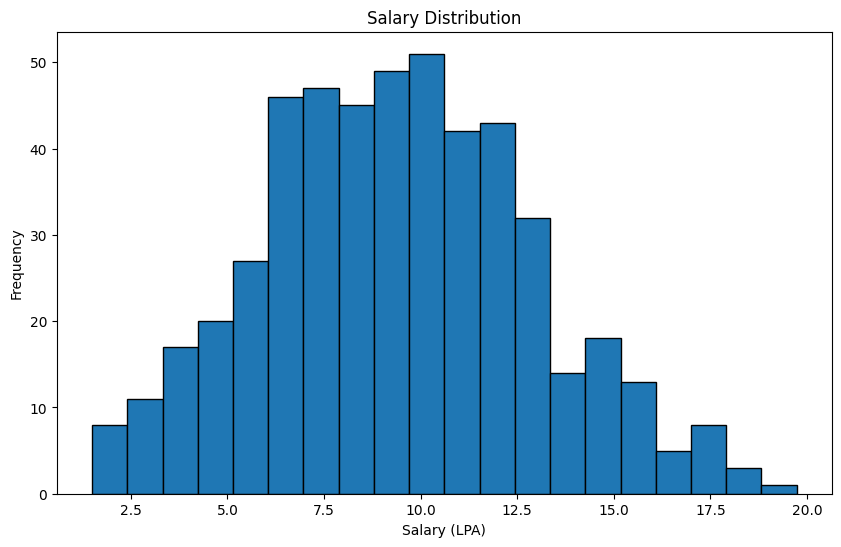

In [16]:
#Salary Distribution Histogram
plt.figure(figsize=(10, 6))

plt.hist(
    df["Salary_LPA"],
    bins=20,
    edgecolor="black"
)

plt.title("Salary Distribution")
plt.xlabel("Salary (LPA)")
plt.ylabel("Frequency")

plt.show()

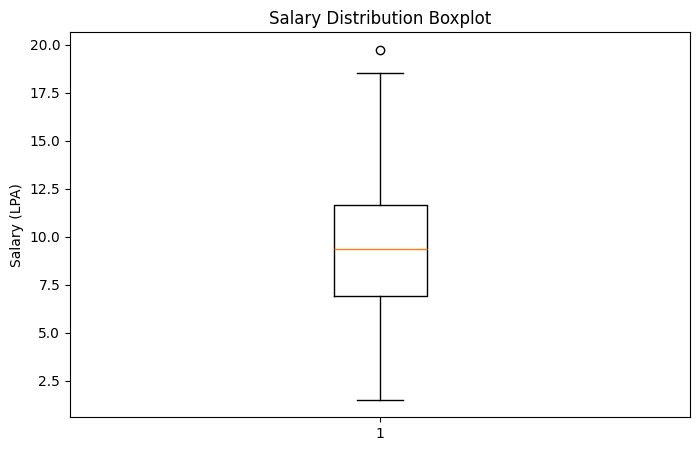

In [17]:
#Salary Boxplot
plt.figure(figsize=(8, 5))

plt.boxplot(df["Salary_LPA"])

plt.title("Salary Distribution Boxplot")
plt.ylabel("Salary (LPA)")

plt.show()

In [18]:
#Top Job Titles
job_counts = df["Job_Title"].value_counts()

print(job_counts)

Job_Title
Data Scientist               68
Machine Learning Engineer    67
Data Analyst                 63
Software Engineer            62
AI Engineer                  61
Data Engineer                61
Business Analyst             61
Python Developer             57
Name: count, dtype: int64


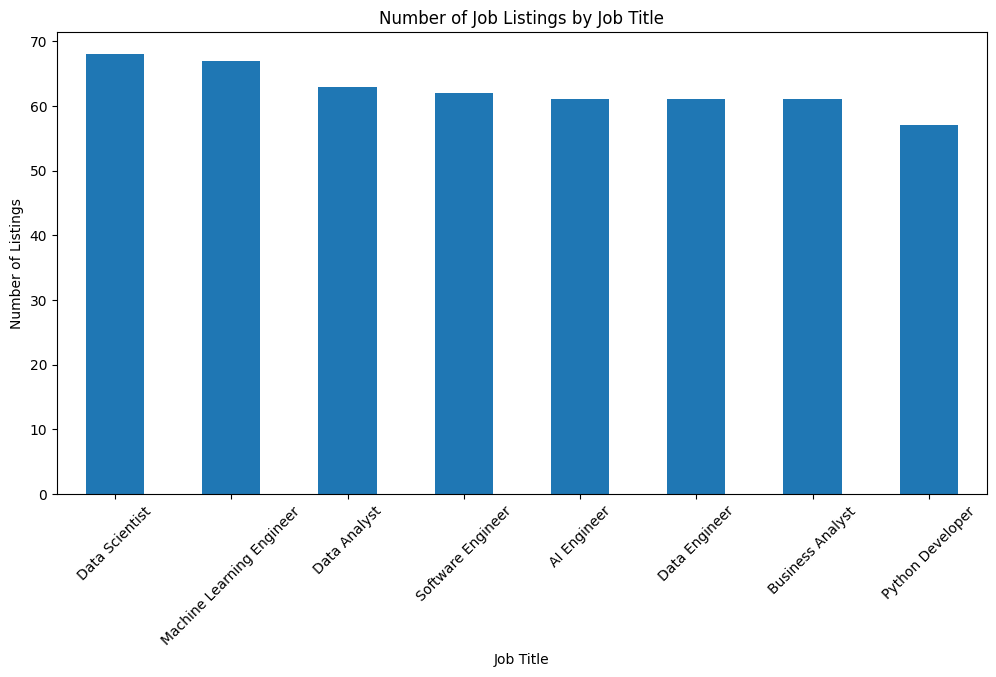

In [19]:
#Job Listings by Job Title
job_counts = df["Job_Title"].value_counts()

plt.figure(figsize=(12, 6))

job_counts.plot(kind="bar")

plt.title("Number of Job Listings by Job Title")
plt.xlabel("Job Title")
plt.ylabel("Number of Listings")

plt.xticks(rotation=45)

plt.show()

In [20]:
#Average Salary by Job Title
avg_salary_job = (
    df.groupby("Job_Title")["Salary_LPA"]
    .mean()
    .sort_values(ascending=False)
)

print(avg_salary_job)

Job_Title
AI Engineer                  12.191475
Machine Learning Engineer    11.607761
Data Scientist               10.182647
Data Engineer                 9.659180
Software Engineer             9.050000
Business Analyst              7.753770
Python Developer              7.703509
Data Analyst                  6.811270
Name: Salary_LPA, dtype: float64


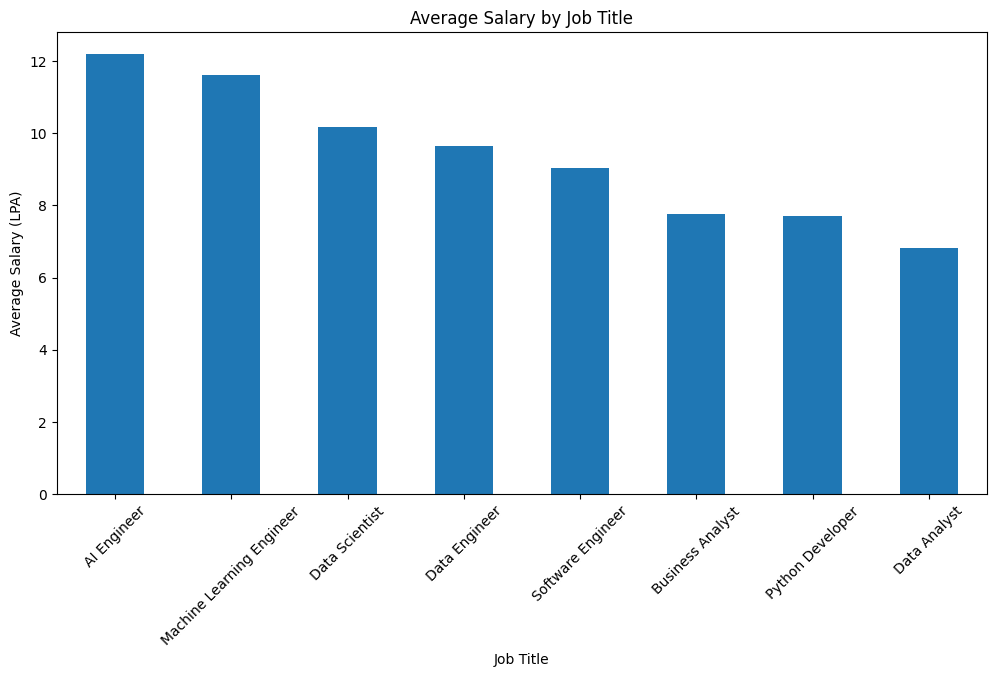

In [21]:
#Visualize Average Salary by Job Title
plt.figure(figsize=(12, 6))

avg_salary_job.plot(kind="bar")

plt.title("Average Salary by Job Title")
plt.xlabel("Job Title")
plt.ylabel("Average Salary (LPA)")

plt.xticks(rotation=45)

plt.show()

In [22]:
#Job Listings by Location
location_counts = df["Location"].value_counts()

print(location_counts)

Location
Bangalore    116
Mumbai        71
Hyderabad     69
Pune          66
Delhi         63
Chennai       43
Ahmedabad     38
Nanded        34
Name: count, dtype: int64


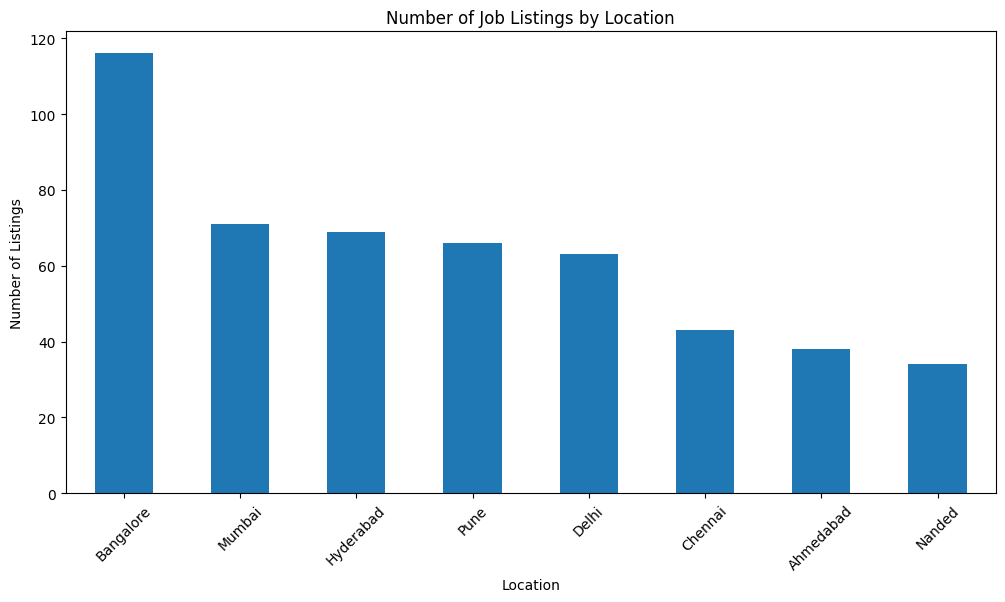

In [23]:
#Visualize Job Listings by Location
plt.figure(figsize=(12, 6))

location_counts.plot(kind="bar")

plt.title("Number of Job Listings by Location")
plt.xlabel("Location")
plt.ylabel("Number of Listings")

plt.xticks(rotation=45)

plt.show()

In [24]:
#Average Salary by Location
avg_salary_location = (
    df.groupby("Location")["Salary_LPA"]
    .mean()
    .sort_values(ascending=False)
)

print(avg_salary_location)

Location
Bangalore    10.832931
Pune         10.094545
Delhi         9.933810
Mumbai        9.851549
Chennai       8.729070
Hyderabad     8.522319
Ahmedabad     7.402105
Nanded        6.250000
Name: Salary_LPA, dtype: float64


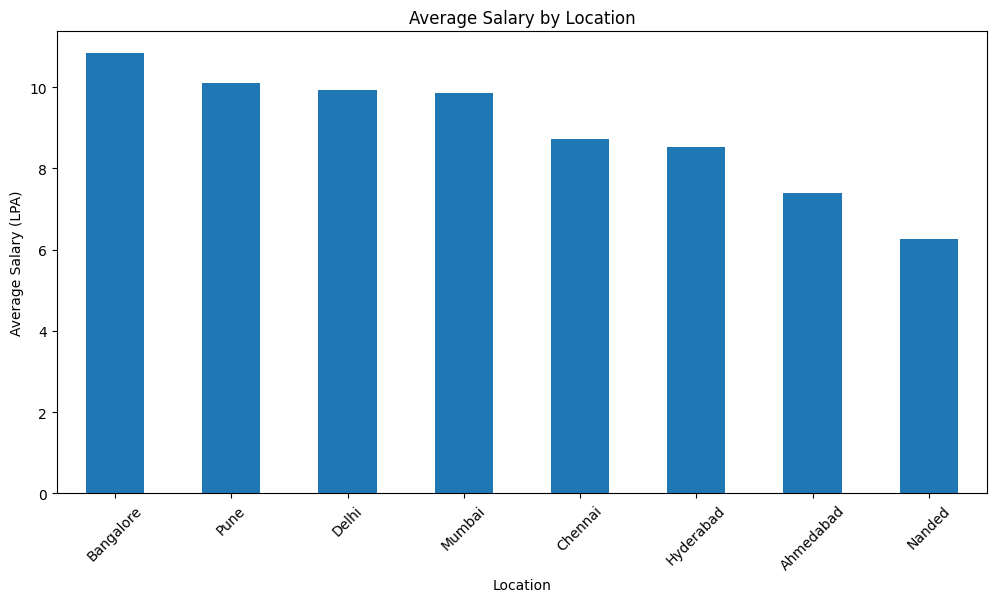

In [25]:
#Visualize Average Salary by Location
plt.figure(figsize=(12, 6))

avg_salary_location.plot(kind="bar")

plt.title("Average Salary by Location")
plt.xlabel("Location")
plt.ylabel("Average Salary (LPA)")

plt.xticks(rotation=45)

plt.show()

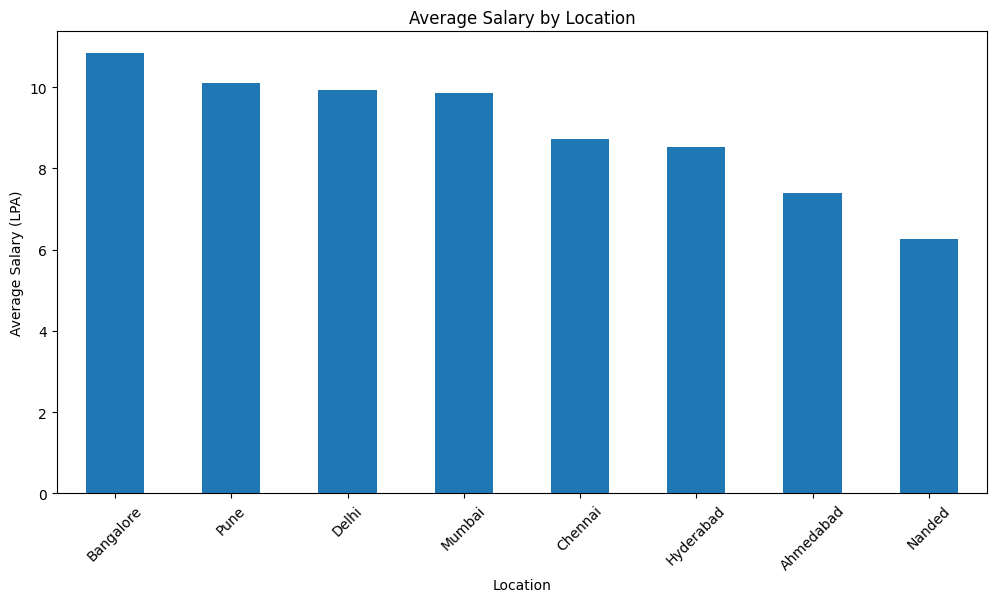

In [26]:
#Visualize Average Salary by Location
plt.figure(figsize=(12, 6))

avg_salary_location.plot(kind="bar")

plt.title("Average Salary by Location")
plt.xlabel("Location")
plt.ylabel("Average Salary (LPA)")

plt.xticks(rotation=45)

plt.show()

In [27]:
#Probability of Salary Above Average
average_salary = df["Salary_LPA"].mean()

prob_above_average = (
    df["Salary_LPA"] > average_salary
).mean()

print("Average Salary:", average_salary)
print("Probability of Salary Above Average:", prob_above_average)

Average Salary: 9.410639999999999
Probability of Salary Above Average: 0.492


In [28]:
#Probability of High Salary
median_salary = df["Salary_LPA"].median()

prob_high_salary = (
    df["Salary_LPA"] > median_salary
).mean()

print("Median Salary:", median_salary)
print("Probability of High Salary:", prob_high_salary)

Median Salary: 9.375
Probability of High Salary: 0.5


In [29]:
#Probability of Job Being in Bangalore
prob_bangalore = (
    df["Location"] == "Bangalore"
).mean()

print("Probability of Job in Bangalore:", prob_bangalore)

Probability of Job in Bangalore: 0.232


In [30]:
high_salary = df["Salary_LPA"] > df["Salary_LPA"].median()

bangalore_jobs = df["Location"] == "Bangalore"

conditional_probability = (
    (high_salary & bangalore_jobs).sum()
    / bangalore_jobs.sum()
)

print(
    "P(High Salary | Bangalore) =",
    conditional_probability
)

P(High Salary | Bangalore) = 0.6206896551724138


In [31]:
#SIMPLE RANDOM SAMPLING
random_sample = df.sample(
    n=100,
    random_state=42
)

random_sample.head()

,Job_ID,Job_Title,Company,Location,Job_Type,Experience_Level,Experience_Years,Education,Skills,Salary_LPA,Posting_Age_Days
361,JOB0362,Business Analyst,NextGen Software,Pune,Full-time,Fresher,0.4,Bachelor's,"Business Analysis, SQL, Power BI",6.38,54
73,JOB0074,Data Scientist,InnovateLabs,Mumbai,Full-time,1-3 Years,2.9,Bachelor's,"Python, Machine Learning, SQL",11.26,1
374,JOB0375,Business Analyst,Insight Analytics,Delhi,Full-time,Fresher,0.0,Bachelor's,"Excel, SQL, Power BI",5.19,49
155,JOB0156,AI Engineer,DigitalWorks Pvt Ltd,Delhi,Contract,3-5 Years,4.5,Bachelor's,"Python, NLP, PyTorch",14.26,19
104,JOB0105,Software Engineer,InnovateLabs,Bangalore,Full-time,Fresher,0.5,Bachelor's,"JavaScript, React, Node.js",7.14,1


In [32]:
print("Population Mean:", df["Salary_LPA"].mean())

print("Sample Mean:", random_sample["Salary_LPA"].mean())

Population Mean: 9.410639999999999
Sample Mean: 9.5743


In [33]:
#SYSTEMATIC SAMPLING
N = len(df)

sample_size = 100

step = N // sample_size

systematic_sample = df.iloc[::step].head(sample_size)

systematic_sample.head()

,Job_ID,Job_Title,Company,Location,Job_Type,Experience_Level,Experience_Years,Education,Skills,Salary_LPA,Posting_Age_Days
0,JOB0001,Python Developer,NextGen Software,Chennai,Full-time,5-8 Years,6.8,Bachelor's,"Python, Pandas, SQL",8.79,3
5,JOB0006,Data Engineer,SmartData Technologies,Hyderabad,Full-time,Fresher,0.8,Bachelor's,"Python, AWS, Spark",7.57,15
10,JOB0011,Business Analyst,NextGen Software,Hyderabad,Full-time,1-3 Years,1.1,Bachelor's,"Excel, SQL, Power BI",5.96,32
15,JOB0016,Data Engineer,CloudEdge Systems,Delhi,Full-time,1-3 Years,1.6,Bachelor's,"Python, AWS, Spark",8.69,23
20,JOB0021,AI Engineer,InnovateLabs,Hyderabad,Internship,1-3 Years,3.0,Bachelor's,"Python, Generative AI, Machine Learning",5.88,16


In [34]:
print("Population Mean:", df["Salary_LPA"].mean())

print("Systematic Sample Mean:",
      systematic_sample["Salary_LPA"].mean())

Population Mean: 9.410639999999999
Systematic Sample Mean: 9.208800000000002


In [35]:
#STRATIFIED SAMPLING


from sklearn.model_selection import train_test_split

stratified_sample, remaining_data = train_test_split(
    df,
    test_size=0.8,
    stratify=df["Job_Title"],
    random_state=42
)

print("Stratified Sample Shape:", stratified_sample.shape)

stratified_sample.head()

Stratified Sample Shape: (100, 11)


,Job_ID,Job_Title,Company,Location,Job_Type,Experience_Level,Experience_Years,Education,Skills,Salary_LPA,Posting_Age_Days
401,JOB0402,AI Engineer,TechNova Solutions,Pune,Full-time,8+ Years,8.3,Master's,"Python, NLP, PyTorch",16.44,55
145,JOB0146,Data Analyst,InnovateLabs,Mumbai,Full-time,1-3 Years,2.2,Master's,"Python, SQL, Statistics",6.90,59
264,JOB0265,Machine Learning Engineer,Insight Analytics,Bangalore,Contract,1-3 Years,2.2,Bachelor's,"Python, Machine Learning, TensorFlow",13.00,51
311,JOB0312,Python Developer,Insight Analytics,Delhi,Full-time,1-3 Years,2.6,PhD,"Python, Flask, APIs",8.42,17
281,JOB0282,AI Engineer,NextGen Software,Pune,Part-time,Fresher,0.6,Bachelor's,"Python, Generative AI, Machine Learning",6.32,18


In [36]:
#CLUSTER SAMPLING
np.random.seed(42)

clusters = df["Location"].unique()

selected_clusters = np.random.choice(
    clusters,
    size=3,
    replace=False
)

print("Selected Clusters:")
print(selected_clusters)

Selected Clusters:
['Bangalore' 'Delhi' 'Chennai']


In [37]:
cluster_sample = df[
    df["Location"].isin(selected_clusters)
]

print("Cluster Sample Shape:", cluster_sample.shape)

cluster_sample.head()

Cluster Sample Shape: (222, 11)


,Job_ID,Job_Title,Company,Location,Job_Type,Experience_Level,Experience_Years,Education,Skills,Salary_LPA,Posting_Age_Days
0,JOB0001,Python Developer,NextGen Software,Chennai,Full-time,5-8 Years,6.8,Bachelor's,"Python, Pandas, SQL",8.79,3
1,JOB0002,Data Engineer,Insight Analytics,Bangalore,Full-time,5-8 Years,5.6,Bachelor's,"Python, AWS, Spark",12.15,44
8,JOB0009,AI Engineer,TechNova Solutions,Delhi,Full-time,3-5 Years,4.9,Master's,"Python, Deep Learning, TensorFlow",13.65,23
15,JOB0016,Data Engineer,CloudEdge Systems,Delhi,Full-time,1-3 Years,1.6,Bachelor's,"Python, AWS, Spark",8.69,23
19,JOB0020,AI Engineer,InnovateLabs,Bangalore,Full-time,5-8 Years,5.6,Master's,"Python, Generative AI, Machine Learning",17.09,26


In [38]:
#CLT
population_mean = df["Salary_LPA"].mean()

sample_size = 30
num_samples = 1000

sample_means = []

for i in range(num_samples):

    sample = df["Salary_LPA"].sample(
        n=sample_size,
        replace=True
    )

    sample_means.append(sample.mean())

sample_means = np.array(sample_means)

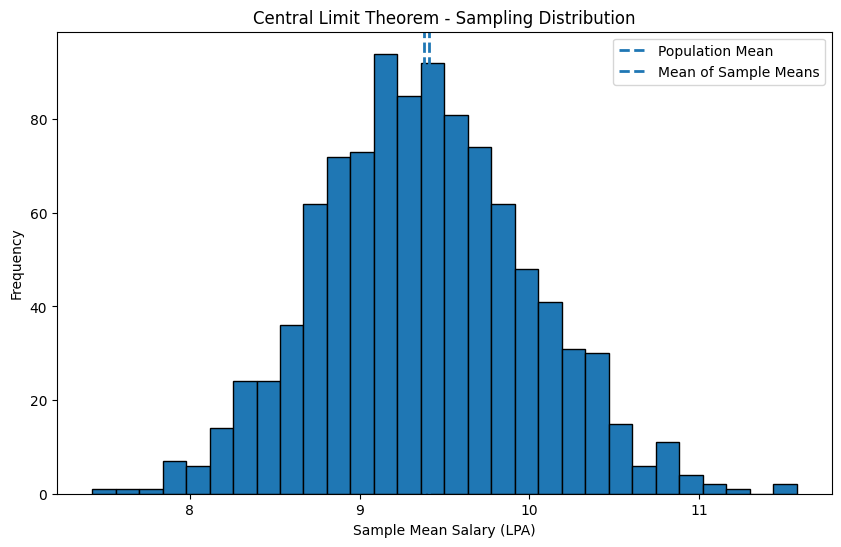

In [39]:
plt.figure(figsize=(10, 6))

plt.hist(
    sample_means,
    bins=30,
    edgecolor="black"
)

plt.axvline(
    population_mean,
    linestyle="dashed",
    linewidth=2,
    label="Population Mean"
)

plt.axvline(
    sample_means.mean(),
    linestyle="dashed",
    linewidth=2,
    label="Mean of Sample Means"
)

plt.title("Central Limit Theorem - Sampling Distribution")

plt.xlabel("Sample Mean Salary (LPA)")
plt.ylabel("Frequency")

plt.legend()

plt.show()

In [40]:
print("Population Mean Salary:",
      population_mean)

print("Mean of Sample Means:",
      sample_means.mean())

print("Standard Deviation of Sample Means:",
      sample_means.std())

Population Mean Salary: 9.410639999999999
Mean of Sample Means: 9.381152666666665
Standard Deviation of Sample Means: 0.6187582919072682


In [41]:
#Confidence Intervals and Hypothesis Testing
import pandas as pd
import numpy as np
from scipy import stats

df = pd.read_csv("online_job_listings_salary_dataset.csv")
df = df.drop_duplicates().copy()

salary = df["Salary_LPA"].dropna()

n = len(salary)
sample_mean = salary.mean()
sample_std = salary.std(ddof=1)
standard_error = stats.sem(salary)

# 95% Confidence Interval
t_critical = stats.t.ppf(0.975, df=n - 1)

lower = sample_mean - t_critical * standard_error
upper = sample_mean + t_critical * standard_error

print("Mean Salary:", sample_mean)
print("95% Confidence Interval:", lower, "to", upper)

# One-sample t-test
t_stat, p_value = stats.ttest_1samp(salary, popmean=10)

print("T-statistic:", t_stat)
print("P-value:", p_value)

if p_value < 0.05:
    print("Reject the null hypothesis")
else:
    print("Fail to reject the null hypothesis")

# Approximate Z-test
z_stat = (sample_mean - 10) / (sample_std / np.sqrt(n))
z_pvalue = 2 * (1 - stats.norm.cdf(abs(z_stat)))

print("Z-statistic:", z_stat)
print("Z-test P-value:", z_pvalue)

Mean Salary: 9.410639999999999
95% Confidence Interval: 9.104111137007752 to 9.717168862992246
T-statistic: -3.777565683600187
P-value: 0.00017747396734411002
Reject the null hypothesis
Z-statistic: -3.777565683600186
Z-test P-value: 0.00015836874517671795


In [43]:
#Chi-Square, ANOVA, Correlation and Covariance
import pandas as pd
from scipy import stats

df = pd.read_csv("online_job_listings_salary_dataset.csv")
df = df.drop_duplicates().copy()

# Chi-square test
table = pd.crosstab(df["Job_Title"], df["Job_Type"])

chi2, p, dof, expected = stats.chi2_contingency(table)

print("Chi-Square Statistic:", chi2)
print("P-value:", p)

if p < 0.05:
    print("Significant association between Job Title and Job Type")
else:
    print("No statistically significant association detected")

# ANOVA
df["Salary_LPA"] = df["Salary_LPA"].fillna(
    df["Salary_LPA"].median()
)

groups = [
    group["Salary_LPA"].values
    for _, group in df.groupby("Job_Title")
]

f_stat, anova_p = stats.f_oneway(*groups)

print("ANOVA F-statistic:", f_stat)
print("ANOVA P-value:", anova_p)

if anova_p < 0.05:
    print("At least one job title has a different mean salary")
else:
    print("No statistically significant difference detected")

Chi-Square Statistic: 36.519707614454845
P-value: 0.01910039625387944
Significant association between Job Title and Job Type
ANOVA F-statistic: 25.285274156102698
ANOVA P-value: 1.5890635471333432e-29
At least one job title has a different mean salary


In [44]:
#Correlation and variance
import pandas as pd

df = pd.read_csv("online_job_listings_salary_dataset.csv")

columns = [
    "Experience_Years",
    "Salary_LPA",
    "Posting_Age_Days"
]

print("Covariance Matrix:")
print(df[columns].cov())

print("Correlation Matrix:")
print(df[columns].corr())

Covariance Matrix:
                  Experience_Years  Salary_LPA  Posting_Age_Days
Experience_Years          8.250710    4.804144          2.798711
Salary_LPA                4.804144   12.075292          0.500492
Posting_Age_Days          2.798711    0.500492        297.921892
Correlation Matrix:
                  Experience_Years  Salary_LPA  Posting_Age_Days
Experience_Years          1.000000    0.481306          0.056450
Salary_LPA                0.481306    1.000000          0.008344
Posting_Age_Days          0.056450    0.008344          1.000000


In [45]:
import pandas as pd
from scipy import stats

df = pd.read_csv("online_job_listings_salary_dataset.csv")

df = df[
    ["Experience_Years", "Salary_LPA"]
].dropna()

# Pearson correlation
r, p1 = stats.pearsonr(
    df["Experience_Years"],
    df["Salary_LPA"]
)

print("Pearson Correlation:", r)
print("Pearson P-value:", p1)

# Spearman correlation
rho, p2 = stats.spearmanr(
    df["Experience_Years"],
    df["Salary_LPA"]
)

print("Spearman Correlation:", rho)
print("Spearman P-value:", p2)

if p1 < 0.05:
    print("Pearson correlation is statistically significant")
else:
    print("Pearson correlation is not statistically significant")

if p2 < 0.05:
    print("Spearman correlation is statistically significant")
else:
    print("Spearman correlation is not statistically significant")

Pearson Correlation: 0.4813063153857252
Pearson P-value: 1.2106089628979161e-30
Spearman Correlation: 0.46231115968834835
Spearman P-value: 4.158704469715976e-28
Pearson correlation is statistically significant
Spearman correlation is statistically significant


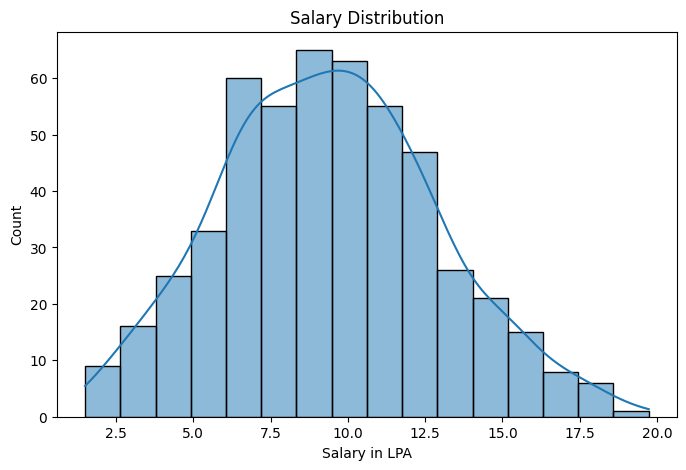

In [48]:
import seaborn as sns
#salary distribution
plt.figure(figsize=(8, 5))

sns.histplot(
    df["Salary_LPA"],
    kde=True
)

plt.title("Salary Distribution")
plt.xlabel("Salary in LPA")
plt.show()

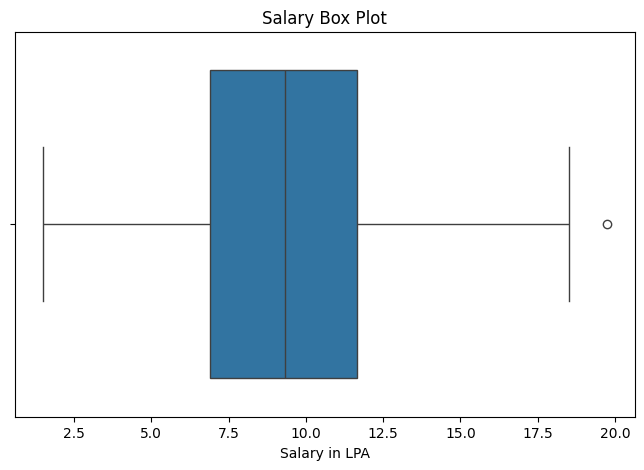

In [49]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    x=df["Salary_LPA"]
)

plt.title("Salary Box Plot")
plt.xlabel("Salary in LPA")
plt.show()

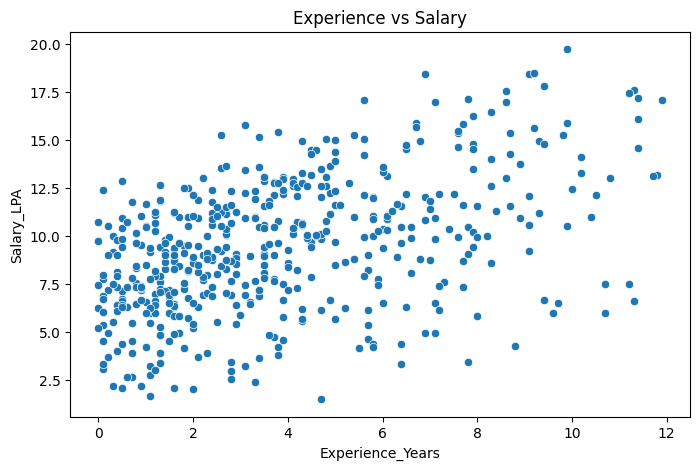

In [50]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Experience_Years",
    y="Salary_LPA"
)

plt.title("Experience vs Salary")
plt.show()

In [52]:
#Covariance analysis
# Dynamically select numeric columns currently present in df
current_numerical_columns = df.select_dtypes(include=np.number).columns
covariance = df[current_numerical_columns].cov()

print("Covariance Matrix:")
display(covariance)

Covariance Matrix:


,Experience_Years,Salary_LPA
Experience_Years,8.250710,4.804144
Salary_LPA,4.804144,12.075292


In [54]:
import pandas as pd
import numpy as np

# 1. Reload the dataset to restore all columns
df = pd.read_csv('online_job_listings_salary_dataset.csv')

# 2. Re-apply previous preprocessing steps (drop duplicates)
df = df.drop_duplicates()

# 3. Handle missing values for numerical features
numerical_cols = df.select_dtypes(include=np.number).columns
for col in numerical_cols:
    df[col] = df[col].fillna(df[col].median())

# 4. Handle missing values for categorical features
categorical_cols = df.select_dtypes(include='object').columns
for col in categorical_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

# 5. Define features and target
features = [
    "Job_Title",
    "Location",
    "Job_Type",
    "Experience_Level",
    "Experience_Years",
    "Education",
    "Skills",
    "Posting_Age_Days"
]

X = df[features]
y = df["Salary_LPA"]

print("Input features:")
display(X.head())

print("Target salary:")
display(y.head())

Input features:


,Job_Title,Location,Job_Type,Experience_Level,Experience_Years,Education,Skills,Posting_Age_Days
0,Python Developer,Chennai,Full-time,5-8 Years,6.8,Bachelor's,"Python, Pandas, SQL",3
1,Data Engineer,Bangalore,Full-time,5-8 Years,5.6,Bachelor's,"Python, AWS, Spark",44
2,Data Analyst,Mumbai,Internship,1-3 Years,1.1,Bachelor's,"SQL, Excel, Tableau",57
3,Machine Learning Engineer,Ahmedabad,Internship,1-3 Years,1.1,PhD,"Python, PyTorch, AWS",26
4,Business Analyst,Mumbai,Full-time,1-3 Years,1.2,Bachelor's,"SQL, Tableau, Excel",6


Target salary:


,Salary_LPA
0,8.79
1,12.15
2,2.77
3,3.23
4,6.99


In [58]:
# 1. Split data into train and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 2. Define preprocessing for numeric and categorical columns
numeric_features = ["Experience_Years", "Posting_Age_Days"]
categorical_features = ["Job_Title", "Location", "Job_Type", "Experience_Level", "Education", "Skills"]

preprocessor = ColumnTransformer(
    transformers=[
        ("num", SimpleImputer(strategy="median"), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_features)
    ]
)

# 3. Define models to train
models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(random_state=42, n_estimators=100)
}

# 4. Train and evaluate each model
for name, model in models.items():
    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("regressor", model)
    ])

    # Train the pipeline
    pipeline.fit(X_train, y_train)

    # Make predictions
    y_pred = pipeline.predict(X_test)

    # Evaluate metrics
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)

    print(f"=== {name} ===")
    print(f"Mean Absolute Error (MAE): {mae:.3f} LPA")
    print(f"Root Mean Squared Error (RMSE): {rmse:.3f} LPA")
    print(f"R2 Score: {r2:.3f}\n")

=== Linear Regression ===
Mean Absolute Error (MAE): 0.901 LPA
Root Mean Squared Error (RMSE): 1.114 LPA
R2 Score: 0.869

=== Decision Tree ===
Mean Absolute Error (MAE): 1.591 LPA
Root Mean Squared Error (RMSE): 2.179 LPA
R2 Score: 0.498

=== Random Forest ===
Mean Absolute Error (MAE): 1.048 LPA
Root Mean Squared Error (RMSE): 1.274 LPA
R2 Score: 0.828



In [55]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

Training data shape: (400, 8)
Testing data shape: (100, 8)


In [59]:
from sklearn.preprocessing import StandardScaler

numerical_features = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = [
    col for col in X.columns
    if col not in numerical_features
]

numerical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numerical_transformer, numerical_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Numerical features:", numerical_features)
print("Categorical features:", categorical_features)

Numerical features: ['Experience_Years', 'Posting_Age_Days']
Categorical features: ['Job_Title', 'Location', 'Job_Type', 'Experience_Level', 'Education', 'Skills']


In [62]:
from sklearn.linear_model import Ridge, Lasso

models = {
    "Multiple Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=1.0),
    "Lasso Regression": Lasso(alpha=0.01, max_iter=10000),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        random_state=42
    )
}

results = []
trained_models = {}

for name, model in models.items():

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)

    y_pred = pipeline.predict(X_test)

    mae = mean_absolute_error(y_test, y_pred)

    mse = mean_squared_error(y_test, y_pred)

    rmse = np.sqrt(mse)

    r2 = r2_score(y_test, y_pred)

    results.append({
        "Model": name,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2 Score": r2
    })

    trained_models[name] = pipeline

    print("\nModel:", name)
    print("MAE:", round(mae, 4))
    print("MSE:", round(mse, 4))
    print("RMSE:", round(rmse, 4))
    print("R2 Score:", round(r2, 4))


Model: Multiple Linear Regression
MAE: 0.9007
MSE: 1.242
RMSE: 1.1145
R2 Score: 0.8687

Model: Ridge Regression
MAE: 0.901
MSE: 1.2407
RMSE: 1.1139
R2 Score: 0.8688

Model: Lasso Regression
MAE: 0.8752
MSE: 1.1612
RMSE: 1.0776
R2 Score: 0.8773

Model: Decision Tree
MAE: 1.6388
MSE: 4.7299
RMSE: 2.1748
R2 Score: 0.5

Model: Random Forest
MAE: 1.0329
MSE: 1.5839
RMSE: 1.2585
R2 Score: 0.8326


In [63]:
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="RMSE",
    ascending=True
)

display(results_df)

,Model,MAE,MSE,RMSE,R2 Score
2,Lasso Regression,0.875198,1.161187,1.077584,0.877257
1,Ridge Regression,0.901032,1.240742,1.113886,0.868848
0,Multiple Linear Regression,0.900742,1.242044,1.114470,0.868710
4,Random Forest,1.032889,1.583910,1.258535,0.832574
3,Decision Tree,1.638800,4.729950,2.174845,0.500023


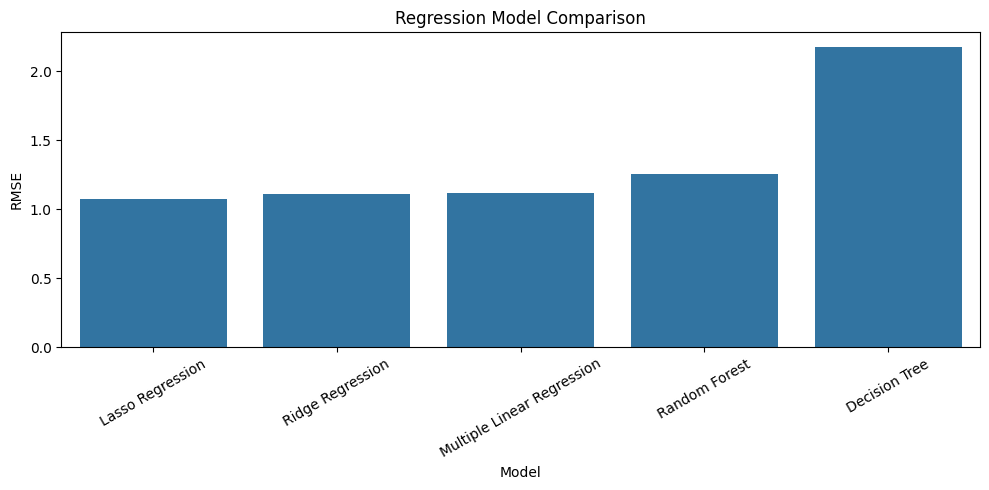

In [64]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=results_df,
    x="Model",
    y="RMSE"
)

plt.title("Regression Model Comparison")
plt.ylabel("RMSE")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [65]:
best_model_name = results_df.iloc[0]["Model"]

best_model = trained_models[best_model_name]

print("Best Regression Model:", best_model_name)

y_pred_best = best_model.predict(X_test)

print("MAE:", mean_absolute_error(y_test, y_pred_best))

print("MSE:", mean_squared_error(y_test, y_pred_best))

print(
    "RMSE:",
    np.sqrt(mean_squared_error(y_test, y_pred_best))
)

print("R2 Score:", r2_score(y_test, y_pred_best))

Best Regression Model: Lasso Regression
MAE: 0.8751979135845835
MSE: 1.161186720900271
RMSE: 1.0775837419431824
R2 Score: 0.8772573814697175


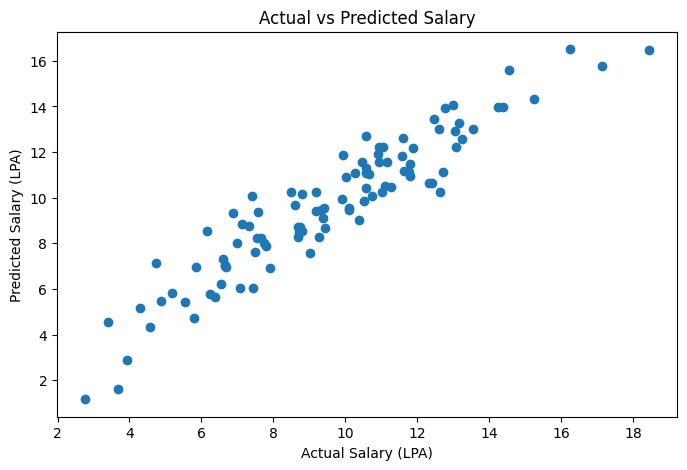

In [66]:
#Actual versus predicted salary
plt.figure(figsize=(8, 5))

plt.scatter(
    y_test,
    y_pred_best
)

plt.xlabel("Actual Salary (LPA)")
plt.ylabel("Predicted Salary (LPA)")
plt.title("Actual vs Predicted Salary")

plt.show()

In [68]:
import joblib

joblib.dump(
    best_model,
    "best_salary_regressor.joblib"
)

print("Best regression model saved successfully.")

Best regression model saved successfully.


In [69]:
files.download("best_salary_regressor.joblib")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [70]:
loaded_model = joblib.load(
    "best_salary_regressor.joblib"
)

sample = X_test.iloc[[0]]

prediction = loaded_model.predict(sample)[0]

print("Input Data:")
display(sample)

print("Actual Salary:", y_test.iloc[0], "LPA")

print("Predicted Salary:", round(prediction, 2), "LPA")

Input Data:


,Job_Title,Location,Job_Type,Experience_Level,Experience_Years,Education,Skills,Posting_Age_Days
361,Business Analyst,Pune,Full-time,Fresher,0.4,Bachelor's,"Business Analysis, SQL, Power BI",54


Actual Salary: 6.38 LPA
Predicted Salary: 5.65 LPA


In [71]:
#Create a salary prediction interface using Gradio
!pip -q install gradio

In [72]:
import gradio as gr
import pandas as pd
import joblib

best_model = joblib.load(
    "best_salary_regressor.joblib"
)

def predict_salary(
    job_title,
    location,
    job_type,
    experience_level,
    experience_years,
    education,
    skills,
    posting_age_days
):

    input_data = pd.DataFrame([{
        "Job_Title": job_title,
        "Location": location,
        "Job_Type": job_type,
        "Experience_Level": experience_level,
        "Experience_Years": experience_years,
        "Education": education,
        "Skills": skills,
        "Posting_Age_Days": posting_age_days
    }])

    prediction = best_model.predict(input_data)[0]

    return "Estimated Salary: ₹" + str(round(prediction, 2)) + " LPA"

demo = gr.Interface(
    fn=predict_salary,
    inputs=[
        gr.Dropdown(
            choices=sorted(df["Job_Title"].unique().tolist()),
            label="Job Title"
        ),
        gr.Dropdown(
            choices=sorted(df["Location"].unique().tolist()),
            label="Location"
        ),
        gr.Dropdown(
            choices=sorted(df["Job_Type"].unique().tolist()),
            label="Job Type"
        ),
        gr.Dropdown(
            choices=sorted(df["Experience_Level"].unique().tolist()),
            label="Experience Level"
        ),
        gr.Number(
            label="Experience in Years",
            value=2
        ),
        gr.Dropdown(
            choices=sorted(df["Education"].unique().tolist()),
            label="Education"
        ),
        gr.Textbox(
            label="Skills",
            value="Python, SQL"
        ),
        gr.Number(
            label="Posting Age in Days",
            value=10
        )
    ],
    outputs=gr.Textbox(label="Predicted Salary"),
    title="Job Salary Prediction System",
    description="Estimate salary using job-related information."
)

demo.launch()

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://30294a4cb2474e4f8a.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
